In [1]:
!pip install -q ultralytics insightface opencv-python pandas numpy matplotlib

In [23]:
from pathlib import Path
import pickle
import time

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from ultralytics import YOLO
from insightface.app import FaceAnalysis

In [35]:
from sklearn.datasets import fetch_lfw_people

print("Loading LFW dataset...")

lfw = fetch_lfw_people(
    min_faces_per_person=20,
    resize=0.5,
    color=True
)

print("LFW loaded.")
print("Images:", len(lfw.images))
print("People:", len(lfw.target_names))

Loading LFW dataset...
LFW loaded.
Images: 3023
People: 62


In [24]:
PROJECT_DIR = Path(r"C:\Users\akars\Capstone\AI_Intruder_Capstone")

MODELS_DIR = PROJECT_DIR / "models"
RESULTS_DIR = PROJECT_DIR / "results" / "combined"

RESULTS_DIR.mkdir(parents=True, exist_ok=True)

print("Project:", PROJECT_DIR)
print("Models:", MODELS_DIR)
print("Results:", RESULTS_DIR)

Project: C:\Users\akars\Capstone\AI_Intruder_Capstone
Models: C:\Users\akars\Capstone\AI_Intruder_Capstone\models
Results: C:\Users\akars\Capstone\AI_Intruder_Capstone\results\combined


In [25]:
BUFFALO_S_FILE = MODELS_DIR / "enrollment_db_buffalo_s.pkl"
BUFFALO_L_FILE = MODELS_DIR / "enrollment_db_buffalo_l.pkl"

print("Buffalo-S exists:", BUFFALO_S_FILE.exists())
print("Buffalo-L exists:", BUFFALO_L_FILE.exists())

Buffalo-S exists: True
Buffalo-L exists: False


In [26]:
with open(BUFFALO_S_FILE, "rb") as f:
    enrollment_db = pickle.load(f)

print("Authorized identities:", len(enrollment_db))
print()

for person_id in enrollment_db:
    print(person_id)

Authorized identities: 5

0
1
2
3
4


In [27]:
PERSON_MODEL_NAME = "YOLO26n"
PERSON_MODEL_PATH = "yolo26n.pt"

person_model = YOLO(PERSON_MODEL_PATH)

print("Loaded:", PERSON_MODEL_NAME)

Loaded: YOLO26n


In [28]:
face_app = FaceAnalysis(
    name="buffalo_s",
    providers=["CPUExecutionProvider"]
)

face_app.prepare(ctx_id=-1)

print("Buffalo-S loaded successfully.")

Buffalo-S loaded successfully.


In [29]:
THRESHOLD = 0.50

print("Recognition threshold:", THRESHOLD)

Recognition threshold: 0.5


In [31]:
def cosine_similarity(a, b):
    a = np.asarray(a)
    b = np.asarray(b)

    denominator = (
        np.linalg.norm(a) *
        np.linalg.norm(b)
    )

    if denominator == 0:
        return 0.0

    return float(np.dot(a, b) / denominator)

In [32]:
def cosine_similarity(a, b):
    a = np.asarray(a)
    b = np.asarray(b)

    denominator = (
        np.linalg.norm(a) *
        np.linalg.norm(b)
    )

    if denominator == 0:
        return 0.0

    return float(np.dot(a, b) / denominator)

In [33]:
def identify_face(embedding, database, threshold=0.50):
    
    best_person = None
    best_score = -1.0

    for person_id, stored_embedding in database.items():
        
        score = cosine_similarity(
            embedding,
            stored_embedding
        )

        if score > best_score:
            best_score = score
            best_person = person_id

    if best_score >= threshold:
        return best_person, best_score

    return None, best_score

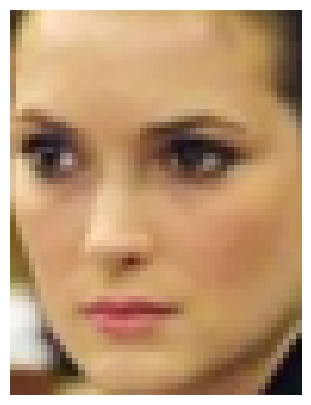

In [36]:
test_idx = 0


test_image = lfw.images[test_idx]

test_image_uint8 = (
    test_image * 255
).clip(0, 255).astype(np.uint8)

plt.figure(figsize=(5, 5))
plt.imshow(test_image_uint8)
plt.axis("off")
plt.show()

In [39]:
def get_embedding(face_app, image):
    """
    Detect the largest face and return its normalized embedding.
    """

    image = np.asarray(image)

    # Convert float image [0, 1] to uint8 [0, 255]
    if image.dtype != np.uint8:
        image = (
            image * 255
        ).clip(0, 255).astype(np.uint8)

    # LFW images are RGB.
    # InsightFace expects BGR.
    image_bgr = cv2.cvtColor(
        image,
        cv2.COLOR_RGB2BGR
    )

    faces = face_app.get(image_bgr)

    if len(faces) == 0:
        return None

    # Select largest face
    face = max(
        faces,
        key=lambda x:
        (x.bbox[2] - x.bbox[0]) *
        (x.bbox[3] - x.bbox[1])
    )

    embedding = face.embedding

    # Normalize embedding
    embedding = embedding / np.linalg.norm(
        embedding
    )

    return embedding

In [40]:
embedding = get_embedding(
    face_app,
    test_image
)

if embedding is None:
    print("No face detected.")
else:
    person, score = identify_face(
        embedding,
        enrollment_db,
        THRESHOLD
    )

    print("Predicted:", person)
    print("Similarity:", score)

C:\Users\akars\Capstone\test\YOLO11\myvenv\Lib\site-packages\insightface\utils\face_align.py:23: FutureWarning: `estimate` is deprecated since version 0.26 and will be removed in version 2.2. Please use `SimilarityTransform.from_estimate` class constructor instead.
  tform.estimate(lmk, dst)


Predicted: None
Similarity: 0.0930435061454773


In [41]:
COCO_IMAGES = PROJECT_DIR / "datasets" / "coco" / "val2017"

test_image_paths = list(
    COCO_IMAGES.glob("*.jpg")
)

print("COCO images found:", len(test_image_paths))

COCO images found: 5000


In [42]:
TEST_IMAGE = test_image_paths[0]

print(TEST_IMAGE)

C:\Users\akars\Capstone\AI_Intruder_Capstone\datasets\coco\val2017\000000000139.jpg


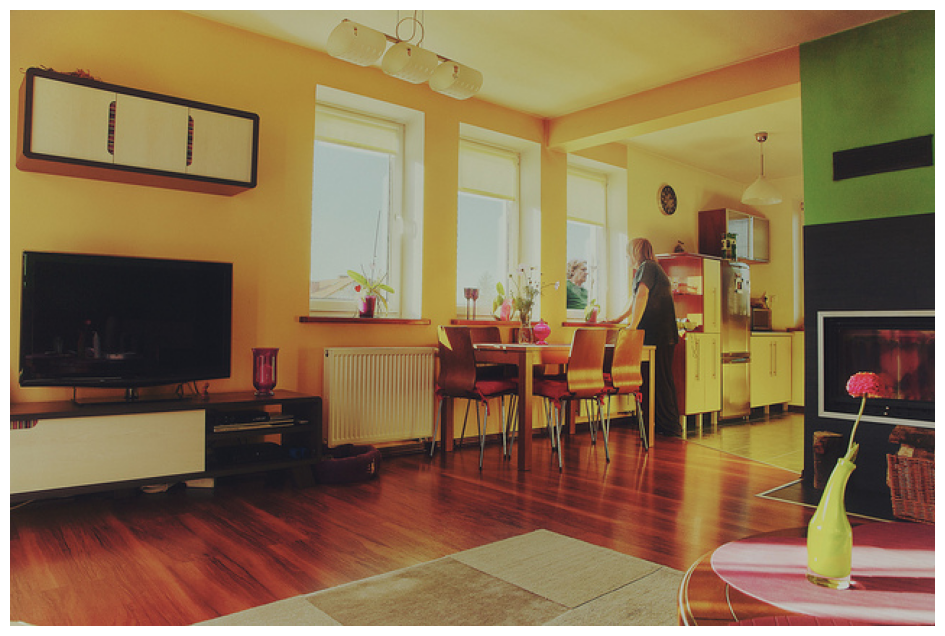

In [43]:
image = cv2.imread(str(TEST_IMAGE))

image_rgb = cv2.cvtColor(
    image,
    cv2.COLOR_BGR2RGB
)

plt.figure(figsize=(12, 8))
plt.imshow(image_rgb)
plt.axis("off")
plt.show()

In [44]:
results = person_model.predict(
    source=str(TEST_IMAGE),
    imgsz=640,
    conf=0.25,
    device="cpu",
    verbose=False
)

result = results[0]

print("Objects detected:", len(result.boxes))

Objects detected: 14


In [45]:
person_boxes = []

for box in result.boxes:
    
    class_id = int(box.cls[0])
    confidence = float(box.conf[0])
    
    if class_id == 0:
        
        x1, y1, x2, y2 = map(
            int,
            box.xyxy[0].tolist()
        )
        
        person_boxes.append({
            "box": (x1, y1, x2, y2),
            "confidence": confidence
        })

print("People detected:", len(person_boxes))

People detected: 1


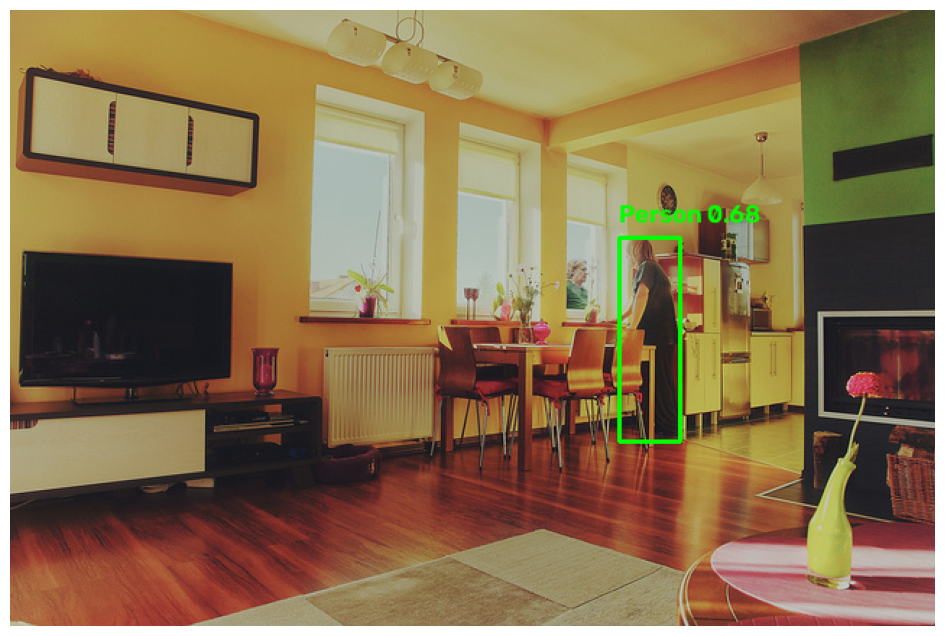

In [46]:
display_image = image.copy()

for person in person_boxes:
    
    x1, y1, x2, y2 = person["box"]
    
    cv2.rectangle(
        display_image,
        (x1, y1),
        (x2, y2),
        (0, 255, 0),
        2
    )
    
    label = f"Person {person['confidence']:.2f}"
    
    cv2.putText(
        display_image,
        label,
        (x1, max(y1 - 10, 20)),
        cv2.FONT_HERSHEY_SIMPLEX,
        0.6,
        (0, 255, 0),
        2
    )

plt.figure(figsize=(12, 8))

plt.imshow(
    cv2.cvtColor(
        display_image,
        cv2.COLOR_BGR2RGB
    )
)

plt.axis("off")
plt.show()

In [47]:
def process_person(
    image,
    person_box,
    face_app,
    enrollment_db,
    threshold=0.50
):
    
    x1, y1, x2, y2 = person_box
    
    h, w = image.shape[:2]
    
    # Keep coordinates inside image
    x1 = max(0, x1)
    y1 = max(0, y1)
    x2 = min(w, x2)
    y2 = min(h, y2)
    
    person_crop = image[y1:y2, x1:x2]
    
    if person_crop.size == 0:
        return None
    
    # InsightFace expects an image
    faces = face_app.get(person_crop)
    
    if len(faces) == 0:
        return {
            "identity": None,
            "similarity": 0.0,
            "face_found": False
        }
    
    # Select largest detected face
    face = max(
        faces,
        key=lambda f:
        (f.bbox[2] - f.bbox[0]) *
        (f.bbox[3] - f.bbox[1])
    )
    
    embedding = face.embedding
    
    embedding = embedding / np.linalg.norm(
        embedding
    )
    
    identity, score = identify_face(
        embedding,
        enrollment_db,
        threshold
    )
    
    return {
        "identity": identity,
        "similarity": score,
        "face_found": True
    }

In [48]:
pipeline_results = []

for person in person_boxes:
    
    result = process_person(
        image,
        person["box"],
        face_app,
        enrollment_db,
        THRESHOLD
    )
    
    pipeline_results.append(result)

print("Processed people:", len(pipeline_results))

Processed people: 1


In [49]:
for i, result in enumerate(pipeline_results):
    
    print(f"Person {i + 1}")
    
    if result is None:
        print("  Processing failed")
        
    elif not result["face_found"]:
        print("  Face: Not detected")
        print("  Status: INTRUDER / UNKNOWN")
        
    elif result["identity"] is None:
        print("  Face: Detected")
        print("  Identity: Unknown")
        print(f"  Similarity: {result['similarity']:.4f}")
        print("  Status: INTRUDER")
        
    else:
        print("  Face: Detected")
        print(f"  Identity: {result['identity']}")
        print(f"  Similarity: {result['similarity']:.4f}")
        print("  Status: AUTHORIZED")
    
    print()

Person 1
  Face: Not detected
  Status: INTRUDER / UNKNOWN



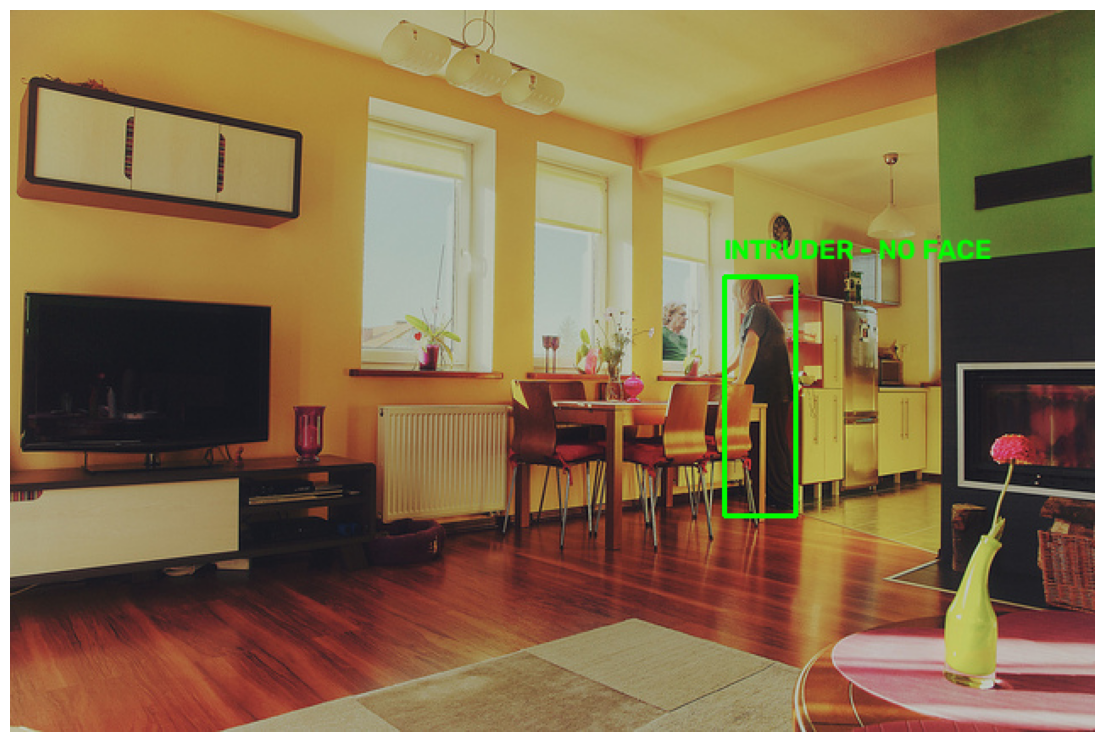

In [50]:
output_image = image.copy()

for person, recognition in zip(
    person_boxes,
    pipeline_results
):
    
    x1, y1, x2, y2 = person["box"]
    
    if recognition is None:
        label = "UNKNOWN"
    
    elif not recognition["face_found"]:
        label = "INTRUDER - NO FACE"
    
    elif recognition["identity"] is None:
        label = (
            f"INTRUDER "
            f"{recognition['similarity']:.2f}"
        )
    
    else:
        label = (
            f"AUTHORIZED: "
            f"{recognition['identity']} "
            f"{recognition['similarity']:.2f}"
        )
    
    cv2.rectangle(
        output_image,
        (x1, y1),
        (x2, y2),
        (0, 255, 0),
        2
    )
    
    cv2.putText(
        output_image,
        label,
        (x1, max(y1 - 10, 25)),
        cv2.FONT_HERSHEY_SIMPLEX,
        0.55,
        (0, 255, 0),
        2
    )

plt.figure(figsize=(14, 10))

plt.imshow(
    cv2.cvtColor(
        output_image,
        cv2.COLOR_BGR2RGB
    )
)

plt.axis("off")
plt.show()

In [51]:
def run_intruder_detection(
    image,
    person_model,
    face_app,
    enrollment_db,
    threshold=0.50,
    image_size=640
):
    
    start_time = time.perf_counter()
    
    # -------------------------
    # Person detection
    # -------------------------
    
    results = person_model.predict(
        source=image,
        imgsz=image_size,
        conf=0.25,
        device="cpu",
        verbose=False
    )
    
    result = results[0]
    
    output = image.copy()
    
    detections = []
    
    # -------------------------
    # Process detected people
    # -------------------------
    
    for box in result.boxes:
        
        class_id = int(box.cls[0])
        
        if class_id != 0:
            continue
        
        confidence = float(box.conf[0])
        
        x1, y1, x2, y2 = map(
            int,
            box.xyxy[0].tolist()
        )
        
        recognition = process_person(
            image,
            (x1, y1, x2, y2),
            face_app,
            enrollment_db,
            threshold
        )
        
        if recognition is None:
            status = "UNKNOWN"
            identity = None
            similarity = 0.0
        
        elif not recognition["face_found"]:
            status = "NO FACE"
            identity = None
            similarity = 0.0
        
        elif recognition["identity"] is None:
            status = "INTRUDER"
            identity = None
            similarity = recognition["similarity"]
        
        else:
            status = "AUTHORIZED"
            identity = recognition["identity"]
            similarity = recognition["similarity"]
        
        detections.append({
            "box": (x1, y1, x2, y2),
            "person_confidence": confidence,
            "identity": identity,
            "similarity": similarity,
            "status": status
        })
        
        # -------------------------
        # Draw result
        # -------------------------
        
        if status == "AUTHORIZED":
            label = (
                f"AUTHORIZED: {identity} "
                f"{similarity:.2f}"
            )
        elif status == "INTRUDER":
            label = (
                f"INTRUDER "
                f"{similarity:.2f}"
            )
        else:
            label = status
        
        cv2.rectangle(
            output,
            (x1, y1),
            (x2, y2),
            (0, 255, 0),
            2
        )
        
        cv2.putText(
            output,
            label,
            (x1, max(y1 - 10, 20)),
            cv2.FONT_HERSHEY_SIMPLEX,
            0.55,
            (0, 255, 0),
            2
        )
    
    # -------------------------
    # Timing
    # -------------------------
    
    elapsed = time.perf_counter() - start_time
    
    latency_ms = elapsed * 1000
    fps = 1 / elapsed if elapsed > 0 else 0
    
    return output, detections, latency_ms, fps

In [52]:
output, detections, latency, fps = run_intruder_detection(
    image=image,
    person_model=person_model,
    face_app=face_app,
    enrollment_db=enrollment_db,
    threshold=THRESHOLD
)

print("Latency:", round(latency, 2), "ms")
print("FPS:", round(fps, 2))
print("People:", len(detections))

Latency: 265.87 ms
FPS: 3.76
People: 1


In [53]:
output, detections, latency, fps = run_intruder_detection(
    image=image,
    person_model=person_model,
    face_app=face_app,
    enrollment_db=enrollment_db,
    threshold=THRESHOLD
)

print("Latency:", round(latency, 2), "ms")
print("FPS:", round(fps, 2))
print("People:", len(detections))

Latency: 259.21 ms
FPS: 3.86
People: 1


In [55]:
if detections:
    
    rows = []
    
    for i, detection in enumerate(detections):
        
        rows.append({
            "Person": i + 1,
            "Detection Confidence": detection[
                "person_confidence"
            ],
            "Identity": detection[
                "identity"
            ],
            "Similarity": detection[
                "similarity"
            ],
            "Status": detection[
                "status"
            ]
        })
    
    results_df = pd.DataFrame(rows)
    
    display(results_df)

else:
    print("No people detected.")

,Person,Detection Confidence,Identity,Similarity,Status
0,1,0.679089,None,0.0,NO FACE


In [56]:
benchmark_images = test_image_paths[:30]

latencies = []
fps_values = []

for image_path in benchmark_images:
    
    frame = cv2.imread(str(image_path))
    
    if frame is None:
        continue
    
    _, _, latency, fps = run_intruder_detection(
        image=frame,
        person_model=person_model,
        face_app=face_app,
        enrollment_db=enrollment_db,
        threshold=THRESHOLD
    )
    
    latencies.append(latency)
    fps_values.append(fps)

C:\Users\akars\Capstone\test\YOLO11\myvenv\Lib\site-packages\insightface\utils\face_align.py:23: FutureWarning: `estimate` is deprecated since version 0.26 and will be removed in version 2.2. Please use `SimilarityTransform.from_estimate` class constructor instead.
  tform.estimate(lmk, dst)


In [58]:
latencies = np.array(latencies)
fps_values = np.array(fps_values)

pipeline_metrics = {
    "Model": PERSON_MODEL_NAME,
    "Face Model": "Buffalo-S",
    "Images Tested": len(latencies),
    "Mean Latency (ms)": latencies.mean(),
    "Median Latency (ms)": np.median(latencies),
    "P95 Latency (ms)": np.percentile(latencies, 95),
    "Mean FPS": fps_values.mean()
}

pipeline_df = pd.DataFrame([pipeline_metrics])

pipeline_df

,Model,Face Model,Images Tested,Mean Latency (ms),Median Latency (ms),P95 Latency (ms),Mean FPS
0,YOLO26n,Buffalo-S,15,4456.038967,1892.0779,16117.9603,2.824101


In [59]:
pipeline_df.to_csv(
    RESULTS_DIR / "combined_pipeline_results.csv",
    index=False
)

print("Saved:")
print(
    RESULTS_DIR /
    "combined_pipeline_results.csv"
)

Saved:
C:\Users\akars\Capstone\AI_Intruder_Capstone\results\combined\combined_pipeline_results.csv


In [60]:
PIPELINES = {
    "YOLO11n + Buffalo-S": {
        "person_model": "yolo11n.pt",
        "face_model": "buffalo_s",
        "enrollment": BUFFALO_S_FILE
    },
    
    "YOLO11n + Buffalo-L": {
        "person_model": "yolo11n.pt",
        "face_model": "buffalo_l",
        "enrollment": BUFFALO_L_FILE
    },
    
    "YOLO26n + Buffalo-S": {
        "person_model": "yolo26n.pt",
        "face_model": "buffalo_s",
        "enrollment": BUFFALO_S_FILE
    },
    
    "YOLO26n + Buffalo-L": {
        "person_model": "yolo26n.pt",
        "face_model": "buffalo_l",
        "enrollment": BUFFALO_L_FILE
    }
}

In [63]:
loaded_pipelines = {}

for name, config in PIPELINES.items():
    
    print("Loading:", name)
    
    detector = YOLO(
        config["person_model"]
    )
    
    face_detector = FaceAnalysis(
        name=config["face_model"],
        providers=["CPUExecutionProvider"]
    )
    
    face_detector.prepare(
        ctx_id=-1
    )
    
    with open(config["enrollment"], "rb") as f:
        database = pickle.load(f)
    
    loaded_pipelines[name] = {
        "detector": detector,
        "face_app": face_detector,
        "database": database
    }

print("\nAll pipelines loaded.")loaded_pipelines = {}

for name, config in PIPELINES.items():
    
    print("Loading:", name)
    
    detector = YOLO(
        config["person_model"]
    )
    
    face_detector = FaceAnalysis(
        name=config["face_model"],
        providers=["CPUExecutionProvider"]
    )
    
    face_detector.prepare(
        ctx_id=-1
    )
    
    with open(config["enrollment"], "rb") as f:
        database = pickle.load(f)
    
    loaded_pipelines[name] = {
        "detector": detector,
        "face_app": face_detector,
        "database": database
    }

print("\nAll pipelines loaded.")

Loading: YOLO11n + Buffalo-S
Loading: YOLO11n + Buffalo-L
Loading: YOLO26n + Buffalo-S
Loading: YOLO26n + Buffalo-L

All pipelines loaded.


In [65]:
all_pipeline_results = []

benchmark_images = test_image_paths[:20]

for pipeline_name, pipeline in loaded_pipelines.items():
    
    print("Testing:", pipeline_name)
    
    detector = pipeline["detector"]
    face_detector = pipeline["face_app"]
    database = pipeline["database"]
    
    times = []
    
    for image_path in benchmark_images:
        
        frame = cv2.imread(
            str(image_path)
        )
        
        if frame is None:
            continue
        
        start = time.perf_counter()
        
        run_intruder_detection(
            image=frame,
            person_model=detector,
            face_app=face_detector,
            enrollment_db=database,
            threshold=THRESHOLD
        )
        
        elapsed = (
            time.perf_counter() -
            start
        )
        
        times.append(elapsed)
    
    times = np.array(times)
    
    all_pipeline_results.append({
        "Pipeline": pipeline_name,
        "Images": len(times),
        "Mean Latency (ms)": times.mean() * 1000,
        "Median Latency (ms)": np.median(times) * 1000,
        "P95 Latency (ms)": np.percentile(times, 95) * 1000,
        "FPS": 1 / times.mean()
    })

Testing: YOLO11n + Buffalo-S


C:\Users\akars\Capstone\test\YOLO11\myvenv\Lib\site-packages\insightface\utils\face_align.py:23: FutureWarning: `estimate` is deprecated since version 0.26 and will be removed in version 2.2. Please use `SimilarityTransform.from_estimate` class constructor instead.
  tform.estimate(lmk, dst)


Testing: YOLO11n + Buffalo-L
Testing: YOLO26n + Buffalo-S
Testing: YOLO26n + Buffalo-L


In [66]:
comparison_df = pd.DataFrame(
    all_pipeline_results
)

comparison_df = comparison_df.sort_values(
    "FPS",
    ascending=False
)

display(comparison_df)


,Pipeline,Images,Mean Latency (ms),Median Latency (ms),P95 Latency (ms),FPS
2,YOLO26n + Buffalo-S,20,2282.038720,771.97845,7569.740810,0.438205
0,YOLO11n + Buffalo-S,20,2448.121500,798.35905,6505.122000,0.408476
3,YOLO26n + Buffalo-L,20,3671.339165,1146.63195,13415.428820,0.272380
1,YOLO11n + Buffalo-L,20,4170.853335,1023.36890,11133.711775,0.239759


In [67]:
comparison_df.to_csv(
    RESULTS_DIR / "pipeline_comparison.csv",
    index=False
)

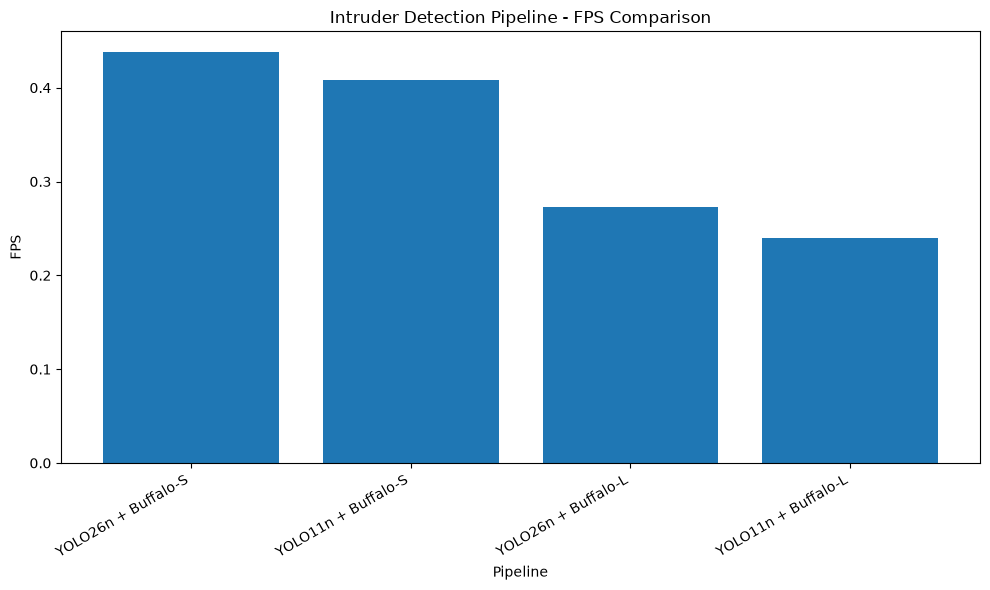

In [68]:
plt.figure(figsize=(10, 6))

plt.bar(
    comparison_df["Pipeline"],
    comparison_df["FPS"]
)

plt.ylabel("FPS")
plt.xlabel("Pipeline")
plt.title("Intruder Detection Pipeline - FPS Comparison")

plt.xticks(
    rotation=30,
    ha="right"
)

plt.tight_layout()
plt.show()

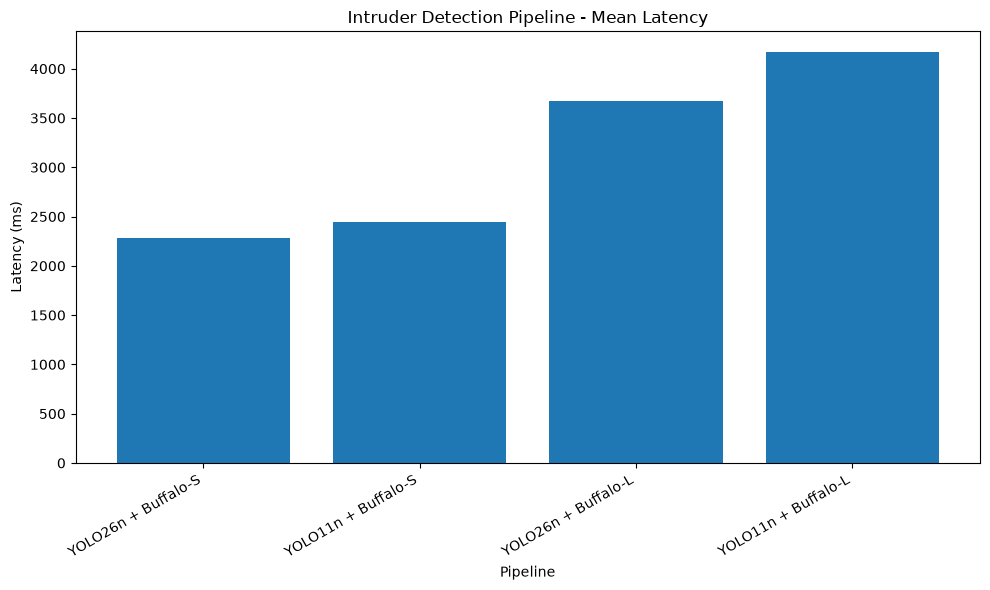

In [69]:
plt.figure(figsize=(10, 6))

plt.bar(
    comparison_df["Pipeline"],
    comparison_df["Mean Latency (ms)"]
)

plt.ylabel("Latency (ms)")
plt.xlabel("Pipeline")
plt.title("Intruder Detection Pipeline - Mean Latency")

plt.xticks(
    rotation=30,
    ha="right"
)

plt.tight_layout()
plt.show()